# Analyse exploratoire des données

## 1. Imports et premières informations sur le dataframe

### Points à retenir :
- Les notes données, et donc les moyennes, sont basées ici uniquement sur les personnes qui ont mis un avis.
- Imdb, plateforme Américaine, note plus favorablement qu'Allocine, plateforme Française
- En février 2026, pour la série 'A knight of the Sevent Kingdoms', 60% des notes données sont des 10. Deux hypothèses :
1. La hype : les épisodes les mieux notés de la série sont sortis en février. Les fans de Game of Thrones ont pu regarder dès la sortie et donner une très bonne note.
2. Une opération pour améliorer la note, avec de nombreux avis donnés, a eu lieu.
- J'ai donc choisi de donner un poids de 80/100 à ces notes pour donner une moyenne plus proche de la réalité.

Voici donc les moyennes pour chaque série avec les intervalles de confiance :
A Knight of the Seven Kingdoms : 8,11 [7.96 - 8.26]
King & Conqueror : 4,38 [3.98 - 4.79]

L'analyse des avis sera faite dans un second temps pour plus d'enseignements.

In [24]:
# Import des librairies pour l'analyse, la datavisualisation et les calculs statistiques
import numpy as np 
import pandas as pd
import seaborn as sns
import os
from scipy.stats import t
from statistics import variance, mean 
from scipy.stats import skew, kurtosis,bootstrap


In [25]:
# Import du dataframe
df = pd.read_csv("../0_Data/2_Clean/Traitement_intermediaire/data_clean.csv")
df.head()

,avis,dates,series,allocine_id,review_id,plateforme,notes
0,Seule le format est décevant. Seulement 6 épis...,2026-02-08,A Knight of the Seven Kingdoms,28230,282301,Allocine,9
1,Très bonne série. Des épisodes trop court tr...,2026-02-07,A Knight of the Seven Kingdoms,28230,282302,Allocine,10
2,J’y ai trouvé du génie ! Pour ceux qui disent ...,2026-02-07,A Knight of the Seven Kingdoms,28230,282303,Allocine,10
3,J'en suis au 4ème épisode et pour l'instant j'...,2026-02-06,A Knight of the Seven Kingdoms,28230,282304,Allocine,10
4,"Encore un grand cru, un bijoux, du caviar, ou ...",2026-02-10,A Knight of the Seven Kingdoms,28230,282305,Allocine,10


In [26]:
# Principales informations
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1622 entries, 0 to 1621
Data columns (total 7 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   avis         1622 non-null   object
 1   dates        1622 non-null   object
 2   series       1622 non-null   object
 3   allocine_id  1622 non-null   int64 
 4   review_id    1622 non-null   int64 
 5   plateforme   1622 non-null   object
 6   notes        1622 non-null   int64 
dtypes: int64(3), object(4)
memory usage: 88.8+ KB


## 2. Distribution des séries et des plateformes

In [27]:
# Ditribution des séries
print(df['series'].value_counts(), '\n')
print(df['series'].value_counts(normalize=True))  # Afficher en proportion 

# Prépondérance importante de la série 'A knight of the seven kingdoms'

series
A Knight of the Seven Kingdoms    1404
King & Conqueror                   218
Name: count, dtype: int64 

series
A Knight of the Seven Kingdoms    0.865598
King & Conqueror                  0.134402
Name: proportion, dtype: float64


In [28]:
print(df['plateforme'].value_counts(), '\n')
print(df['plateforme'].value_counts(normalize=True))

# Prépondérance importante de la plateforme Imdb

plateforme
Imdb        1412
Allocine     210
Name: count, dtype: int64 

plateforme
Imdb        0.87053
Allocine    0.12947
Name: proportion, dtype: float64


In [29]:
display(pd.crosstab(df['series'], df['plateforme']))
display(pd.crosstab(df['series'], df['plateforme'], normalize=True))

# Prépondérance importante de la plateforme Imdb

plateforme,Allocine,Imdb
series,,
A Knight of the Seven Kingdoms,165,1239
King & Conqueror,45,173


plateforme,Allocine,Imdb
series,,
A Knight of the Seven Kingdoms,0.101726,0.763872
King & Conqueror,0.027744,0.106658


In [30]:
# Comparaison des notes par plateforme et par série.

display(df.describe())
print()
print('Statistiques sur la plateforme Allociné :\n', df[df['plateforme'] == 'Allocine']['notes'].describe() )
print()
print('Statistiques sur la plateforme Imdb :\n', df[df['plateforme'] == 'Imdb']['notes'].describe())

# Différences importantes de notation entre allociné et imdb : imdb note nettement plus haut 
# Différence de public ou de pays (fr vs usa) ?

,allocine_id,review_id,notes
count,1622.000000,1.622000e+03,1622.000000
mean,29221.080148,3.328985e+07,7.955610
std,2515.926802,7.965228e+06,2.984104
min,28230.000000,2.823010e+05,1.000000
25%,28230.000000,3.560441e+07,7.000000
50%,28230.000000,3.560481e+07,10.000000
75%,28230.000000,3.560522e+07,10.000000
max,35604.000000,3.560562e+07,10.000000



Statistiques sur la plateforme Allociné :
 count    210.000000
mean       7.947619
std        2.806711
min        1.000000
25%        8.000000
50%        9.000000
75%       10.000000
max       10.000000
Name: notes, dtype: float64

Statistiques sur la plateforme Imdb :
 count    1412.000000
mean        7.956799
std         3.010537
min         1.000000
25%         7.000000
50%        10.000000
75%        10.000000
max        10.000000
Name: notes, dtype: float64


In [31]:
print('Statistiques sur la série : A knight of the seven kingdoms :\n', df[df['series'] == 'A Knight of the Seven Kingdoms']['notes'].describe() )
print()
print('Statistiques sur la série King & Conquerer :\n', df[df['series'] == 'King & Conqueror']['notes'].describe())

# A Knight of the Sevent Kingdoms a des notes nettement meilleures que King & Conqueror.

Statistiques sur la série : A knight of the seven kingdoms :
 count    1404.000000
mean        8.522792
std         2.566614
min         1.000000
25%         8.000000
50%        10.000000
75%        10.000000
max        10.000000
Name: notes, dtype: float64

Statistiques sur la série King & Conquerer :
 count    218.000000
mean       4.302752
std        2.905595
min        1.000000
25%        2.000000
50%        3.000000
75%        7.000000
max       10.000000
Name: notes, dtype: float64


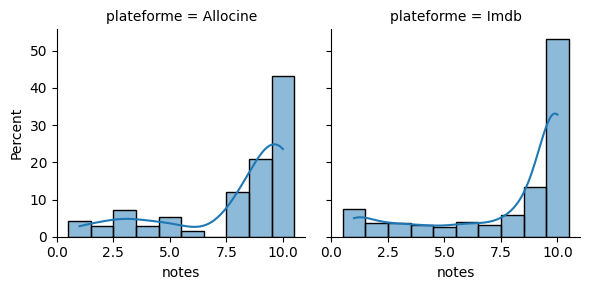

In [32]:
# Visualisons les distributions

g = sns.FacetGrid(df, col="plateforme")
g.map(sns.histplot, 'notes', bins=10, kde=True, stat='percent', discrete=True);

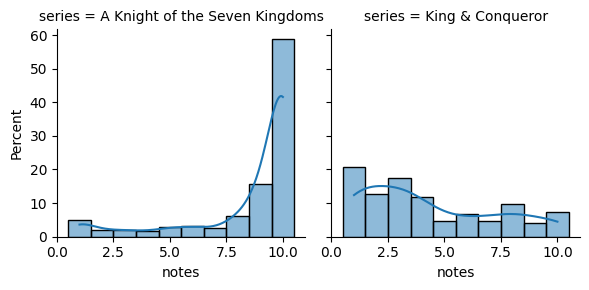

In [33]:
g = sns.FacetGrid(df, col="series")
g.map(sns.histplot, 'notes', bins=10, kde=True, stat='percent', discrete=True);

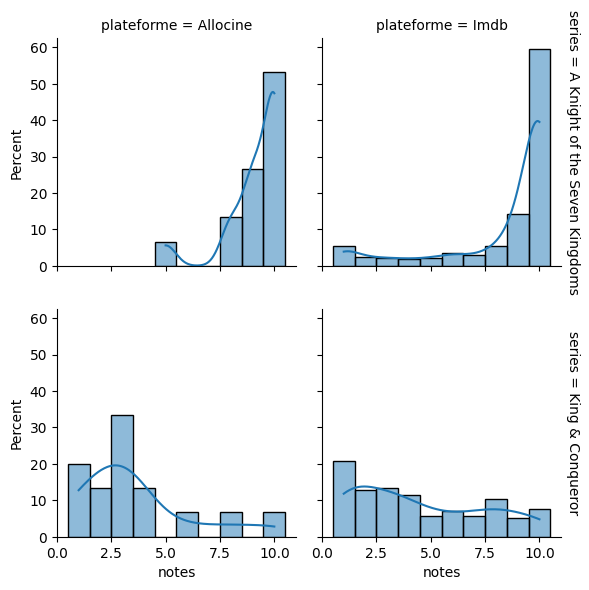

In [34]:
g = sns.FacetGrid(df, col="plateforme", row='series', margin_titles=True)
g.map(sns.histplot, "notes", stat='percent', kde=True, discrete=True);

Pour les deux plateformes, les notes élevées (8 à 10) sont très fortes pour 'A knight of the seven kingdoms' tandis que les notes très faibles (0 à 2) sont plus choisies pour 'King & Conquerer'.

Imdb, plateforme Américaine, a plus de notes positives pour les deux séries. Mais le nombre de 10 pour 'A knight of the seven Kingdom' est impressionant (60%) : la série a été un énorme succès critique.

A l'inverse, Allociné, plateforme française, les notes tendent à être moins positives. C'est particulièrement le cas pour 'King & Conquerer', où les notes entre 0 et 4 sont sur-représentées.

La médiane est révélatrice : elle est de 10 pour Imdb et 7 pour allociné.

## 3. Distribution selon la date

annee-mois
202508      85
202509      56
202510      13
202511      21
202512       3
202601     254
202602    1076
202603     114
Name: count, dtype: int64


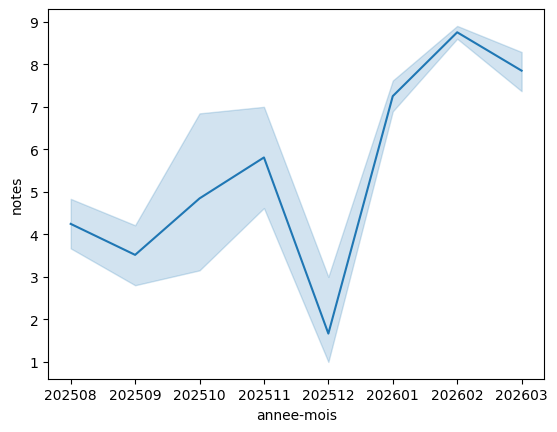

In [35]:
# Regardons si la date a eu un impact sur les notes données

df['dates'] = pd.to_datetime(df['dates']) # Conversion

# Création d'une colonne pour trier selon le format suivant 'YYYYMM'
df['annee-mois'] = df['dates'].dt.strftime('%Y%m')
print(df['annee-mois'].value_counts().sort_index())

# Création graphique
df_dates = df.set_index('annee-mois').sort_index()
sns.lineplot(data=df_dates["notes"].sort_index());

# Nous observons une dynamique différente entre la fin de l'année dernière, avec des notes globalement
# inférieurs à 5, et 2026, où les notes remontent fortement.

In [36]:
# Regardons de plus près les statistiques par mois.

df.groupby(['annee-mois'])['notes'].describe()

,count,mean,std,min,25%,50%,75%,max
annee-mois,,,,,,,,
202508,85.0,4.247059,2.836438,1.0,2.0,3.0,6.0,10.0
202509,56.0,3.517857,2.655978,1.0,1.0,3.0,4.0,10.0
202510,13.0,4.846154,3.411895,1.0,2.0,4.0,8.0,10.0
202511,21.0,5.809524,2.786020,1.0,4.0,6.0,8.0,10.0
202512,3.0,1.666667,1.154701,1.0,1.0,1.0,2.0,3.0
202601,254.0,7.251969,3.083729,1.0,5.0,9.0,10.0,10.0
202602,1076.0,8.753717,2.463451,1.0,9.0,10.0,10.0,10.0
202603,114.0,7.850877,2.521527,1.0,7.0,9.0,10.0,10.0


Dates de sortie des épisodes : 
24 août 2025 au 5 octobre pour King & Conquer sur BBC One, du 19 janvier au 23 février 2026 pour A knight of the seven kingdoms.

Le mois de février, la médiane à 10 est impressionnante. Deux hypothèses ici : 
- Les épisodes sortis en février ont eu un excellent accueil.
- Une campagne pour promouvoir la série a eu lieu pour mettre de bonnes notes, notamment sur Imdb.

Le Quartile de 25% à 9 me met la puce à l'oreille. 

Vérifions si nous retrouvons les mêmes tendances sur les deux plateformes pour la série 'A Knight of the Seven Kingdoms'.

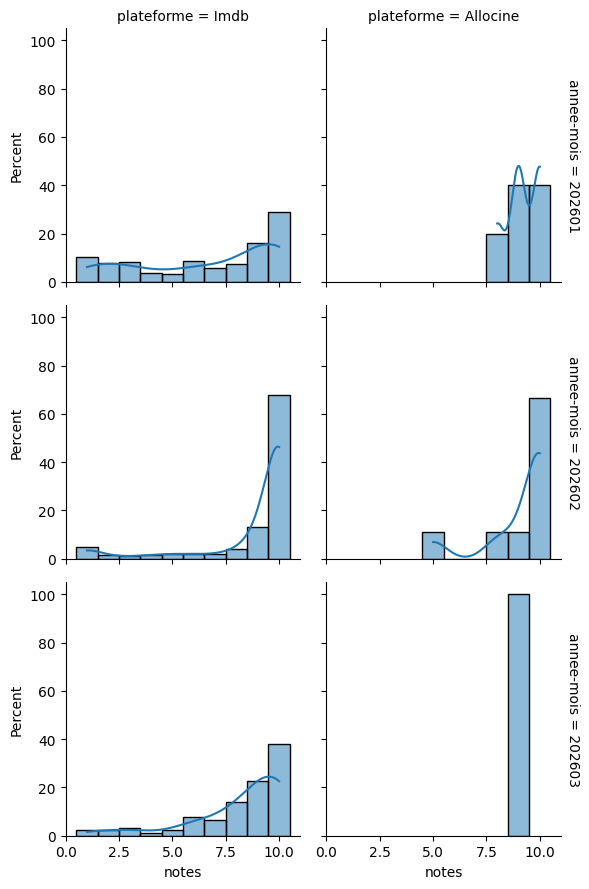

In [37]:
# Création d'un dataframe ciblé sur 2026 et A Knight of the Seven Kindgoms
df_2026_knight = df.loc[(df['dates'].dt.year == 2026) & (df['series'] == 'A Knight of the Seven Kingdoms')]

# Visualisation comparée par mois de 2026
g = sns.FacetGrid(df_2026_knight.sort_values('annee-mois'), col="plateforme", \
                  row='annee-mois', margin_titles=True)
g.map(sns.histplot, "notes", stat='percent', kde=True, discrete=True);

Je pense que mes deux hypothèses sont justes :
1. Les épisodes 3, 4, et 5 de la série ont reçu un très bon accueil : ce sont les meilleurs avec des notes tous supérieurs à 9 dans Imdb.
2. Il est aussi possible que les plus fans de l'univers GOAT aient regardé les épisodes dès leur sortie, et qu'ils soient le plus venus rapidement donner une note positive. Il y a peut-être eu un effet de mode en février.
3. En revanche, je trouve la différence entre février et mars trop différente (environ 60% et 40% de notes à 10). 

Je pense que la hype explique ces notes très fortes. Mais par soucis de pédagogie, je vais baisser le poids des notes données.

## 4. Moyennes des notes par série (avec pondération)

In [38]:
# Statistiques des notes par séries et plateformes avant pondération

print("Statistiques par série")
display(df.groupby(['series'])[('notes')].describe())
print()
print("Statistiques par série x plateforme")
display(df.groupby(['plateforme', 'series'])[('notes')].describe())

Statistiques par série


,count,mean,std,min,25%,50%,75%,max
series,,,,,,,,
A Knight of the Seven Kingdoms,1404.0,8.522792,2.566614,1.0,8.0,10.0,10.0,10.0
King & Conqueror,218.0,4.302752,2.905595,1.0,2.0,3.0,7.0,10.0



Statistiques par série x plateforme


count      mean       std  min  \
plateforme series                                                            
Allocine   A Knight of the Seven Kingdoms   165.0  9.133333  1.313779  5.0   
           King & Conqueror                  45.0  3.600000  2.526226  1.0   
Imdb       A Knight of the Seven Kingdoms  1239.0  8.441485  2.679653  1.0   
           King & Conqueror                 173.0  4.485549  2.975886  1.0   

                                           25%   50%   75%   max  
plateforme series                                                 
Allocine   A Knight of the Seven Kingdoms  9.0  10.0  10.0  10.0  
           King & Conqueror                2.0   3.0   4.0  10.0  
Imdb       A Knight of the Seven Kingdoms  8.0  10.0  10.0  10.0  
           King & Conqueror                2.0   4.0   7.0  10.0

Modifications : donner un poids de 0,8 à la réponse lorsque la note est de 10 pour 'A Knight of the Seven Kingdoms' en février 2026 sur Imdb, et  1 pour les autres.

Une pondération à 80% (baisse de 20%) part d'une hypothèse prudente, que la plupart des notes sont sincères, et que, s'il y a eu une campagne, elle se situe à la marge.

In [39]:
# Initialisation de la colonne avec un poids de 1 pour tous
df['poids'] = 1.0

df.loc[
    (df['plateforme'] == 'Imdb') 
    & (df['series'] == 'A Knight of the Seven Kingdoms') 
    & (df['notes'] == 10)
    & (df['annee-mois'] == '202602')
    , 'poids'
    ] = 0.8

df['poids'].value_counts()

poids
1.0    976
0.8    646
Name: count, dtype: int64

In [40]:
# Nouvelle moyenne pondérée de 'a Knight of the Seven Kingdoms'

df_knight = df[df['series'] == 'A Knight of the Seven Kingdoms']

df_knight_mean = (df_knight['notes'] * df_knight['poids']).sum() / df_knight['poids'].sum()

print(round(df_knight_mean, 2))

# Nous passons donc de 8,29 à 8,11.

8.37


## 5. Intervalles de confiances

Calculons maintenant les intervalles de confiance pour les deux séries.

Avec deux cas de figure : 
1. King & Conquerer : pas de modification du poids des réponses
2. A Knight of the Seven Kingdoms : modifications du poids, donc de l'effectif de réponses.

Aides :
https://claude.ai/chat/f112ba51-f00a-46da-9286-042acd2bc990
https://matthwilhelm.github.io/ProbaStat/Tutoriel_Python.html
https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.bootstrap.html

Sur le skewness et le kurtosis : https://www.datacamp.com/fr/tutorial/understanding-skewness-and-kurtosis


In [41]:
df_king = df[df["series"] == "King & Conqueror"]

print(skew(df_king['notes']))     # asymétrie — idéalement proche de 0
print(kurtosis(df_king['notes'])) # aplatissement — problématique si très élevé

# Asymétrie : les données sont majoritairement inférieures à la moyenne
# Aplatissement : proche de 0, pas de soucis.

0.5983956121116719
-0.9169655335442921


In [42]:
# Cas 1 : King & Conqueror, sans pondération des notes

def int_ech(values, conf=0.95):
    
    n = len(values) # Taille échantillon
    m = np.mean(values) # Moyenne
    s = np.var(values, ddof=1) # Variance

    alpha_half = 1 - (1 - conf) / 2
    ddl = n - 1 # Degré de liberté

    intervalle = np.sqrt(s / n) * t.ppf(alpha_half, ddl)

    return intervalle

intervalle_king = int_ech(df_king['notes'])
intervalle_king_up = np.mean(df_king['notes']) + intervalle_king
intervalle_king_down = np.mean(df_king['notes']) - intervalle_king

print('Intervalle de confiance King & Conqueror : [', intervalle_king_down,'-', intervalle_king_up, ']' )

Intervalle de confiance King & Conqueror : [ 3.914884436168754 - 4.690620150987209 ]


In [ ]:
# Pour A Knight of the Seven Kingdoms

print(skew(df_knight['notes']))     # asymétrie — idéalement proche de 0
print(kurtosis(df_knight['notes'])) # applatissement — problématique si très élevé

# Commentaires à faire

n= np.sum(df_knight['poids']) # Prendre en compte le nouveau poids décidé
m = df_knight_mean # Moyenne agrégée
s = np.var(df_knight['notes'], ddof=1)

conf = 0.95 # Degré de confiance

alpha_half = 1 - (1 - conf) / 2
ddl = n - 1

intervalle_knight = np.sqrt(s / n) * t.ppf(alpha_half, ddl)

intervalle_knight_up = df_knight_mean + intervalle_knight
intervalle_knight_down = df_knight_mean - intervalle_knight

print('Intervalle de confiance A Knight of the Seven Kingdoms : [', intervalle_knight_down,'-', intervalle_knight_up, ']' )

-1.8761934324958134
2.3134816770965
Intervalle de confiance A Knight of the Seven Kingdoms : [ 8.232051728082979 - 8.514104531722477 ]


In [44]:

# Pour le test, vérification avec le bootstrap.

# Ne pas prendre en compte parce que la moyenne n'est pas bonne
result = bootstrap(
    (df_knight['notes'].values,),
    np.mean,
    confidence_level=0.95,
    n_resamples=9999,
    method='percentile'
)
print(result.confidence_interval)

ConfidenceInterval(low=np.float64(8.386752136752136), high=np.float64(8.655270655270655))
